# TASK NO. 4 : Fruit Detection and Classification on Fruits-360

**Name: Luqman Khan**  |  **SID: S2024466054**

### How to read this notebook

```text
Run it from top to bottom. Every "SECTION" below is one step of the task:

  Section 0   Imports and settings (change numbers like EPOCHS here)
  Section 1   Connect Google Drive + save/resume checkpoints
  Section 2   Download and load the Fruits-360 dataset
  Section 3   4(a) Explore the data (class counts, sample images)
  Section 4   Prepare RGB / Grayscale / HSV versions of the images
  Section 5   4(b) Build the CNN, count its parameters, train the RGB model
  Section 6   4(c) Train Grayscale and HSV models, compare with the paper
  Section 7   4(c) Confusion matrix for the apple classes
  Section 8   4(d) Fruit detection (multi-fruit scenes, sliding window, NMS)
  Section 9   Save everything and print the final summary
  Section 10  4(e) Discussion answers

Big idea of the whole task:
  * A CNN CLASSIFIER looks at ONE 100x100 image and says which fruit it is.
  * A DETECTOR must find fruits inside a LARGER picture. We build it by sliding
    a 100x100 window over the picture, classifying every window with the CNN,
    and then removing duplicate boxes (Non-Maximum Suppression).
```

## SECTION 0 : IMPORTS AND SETTINGS

In [1]:
import json

import os

import random

import time

from functools import lru_cache

from pathlib import Path

from types import SimpleNamespace

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

import tensorflow as tf

from matplotlib.patches import Rectangle

from PIL import Image

from sklearn.metrics import confusion_matrix

from tensorflow import keras

try:                                    # `display` exists in Colab / Jupyter
    from IPython.display import display
except ImportError:                     # plain Python: just print instead
    display = print

### Settings you may want to change

In [2]:
SEED = 42

IMAGE_SIZE = (100, 100)          # every fruit image is resized to 100 x 100

BATCH_SIZE = 50

EPOCHS = 25                      # epochs for the three classifiers

DETECTOR_EPOCHS = 10             # epochs for the 121-class detector

SAVE_EVERY_N_EPOCHS = 1          # write a checkpoint to Drive every N epochs

USE_KAGGLEHUB = True             # download the dataset from Kaggle

DATASET_ROOT = None              # OR set a folder that contains Training/ and Test/

COLOUR_SPACES = {"RGB": 3, "Grayscale": 1, "HSV": 3}   # name -> number of channels

PUBLISHED_ACCURACY = {"RGB": 0.9866, "Grayscale": 0.9525, "HSV": 0.9609}

# Detection settings
FRUIT_SIZE = 100                 # size of one fruit / one sliding window

SCENE_SIZE = (500, 350)          # (width, height) of generated scenes

DETECTION_SCENE_COUNT = 50

STRIDES = [10, 20, 40]           # how far the window moves each step

THRESHOLDS = [0.5, 0.7, 0.9]     # minimum confidence to keep a detection

IOU_MATCH = 0.5                  # a detection is correct if IoU >= this

NMS_IOU = 0.3                    # boxes overlapping more than this are merged

### Reproducibility

In [3]:
random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE

### Output folders (inside Colab's temporary storage)

In [4]:
OUTPUT_DIR = Path("/content/Task4_Results")

PLOTS_DIR = OUTPUT_DIR / "plots"

CSV_DIR = OUTPUT_DIR / "csv"

MODELS_DIR = OUTPUT_DIR / "models"

DETECTIONS_DIR = OUTPUT_DIR / "detection_results"

for folder in (PLOTS_DIR, CSV_DIR, MODELS_DIR, DETECTIONS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)

print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
def save_and_show(path, dpi=200, **save_kwargs):
    """Small helper: tidy the layout, save the current figure, then show it."""
    plt.tight_layout()
    plt.savefig(path, dpi=dpi, **save_kwargs)
    plt.show()

## SECTION 1 : GOOGLE DRIVE + CHECKPOINTS

> Colab can disconnect at any time and then everything in /content is lost.
> So while a model trains we keep copying it to Google Drive. After a
> disconnect, run the notebook again: the model is reloaded from Drive and
> training continues from the last finished epoch.

In [6]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = Path("/content/drive/MyDrive/Task4_Checkpoints")
except ImportError:
    print("Not running in Colab - checkpoints will be stored locally instead.")
    CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Checkpoints are stored in:", CHECKPOINT_DIR)

Mounted at /content/drive
Checkpoints are stored in: /content/drive/MyDrive/Task4_Checkpoints


In [7]:
class DriveCheckpoint(keras.callbacks.Callback):
    """Keras callback: after each epoch, record the results and (every N
    epochs) save the full model + training progress to Drive."""

    def __init__(self, ckpt_dir, state, save_every=1):
        super().__init__()
        self.ckpt_dir = Path(ckpt_dir)
        self.state = state                       # progress dictionary (see below)
        self.save_every = save_every
        self._last_saved_epoch = state["epochs_completed"]

    def on_epoch_begin(self, epoch, logs=None):
        self._epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.state["epoch_times"].append(time.time() - self._epoch_start)
        for name, value in (logs or {}).items():
            self.state["history"].setdefault(name, []).append(float(value))
        self.state["epochs_completed"] = epoch + 1

        if (epoch + 1) % self.save_every == 0:
            self._save()

    def on_train_end(self, logs=None):
        if self.state["epochs_completed"] != self._last_saved_epoch:
            self._save()

    def _save(self):
        # Save to a temporary name first, then rename. If Colab disconnects
        # in the middle of saving, the previous good checkpoint stays intact.
        tmp_model = self.ckpt_dir / "tmp_latest.keras"
        self.model.save(str(tmp_model))
        os.replace(tmp_model, self.ckpt_dir / "latest.keras")

        tmp_state = self.ckpt_dir / "state.json.tmp"
        tmp_state.write_text(json.dumps(self.state))
        os.replace(tmp_state, self.ckpt_dir / "state.json")

        self._last_saved_epoch = self.state["epochs_completed"]
        print(f"  -> checkpoint saved to Drive (epoch {self._last_saved_epoch})")

In [8]:
def train_with_checkpoints(name, model, train_ds, val_ds, epochs):
    """Train `model` and keep a checkpoint on Drive.

    * No checkpoint on Drive -> train from epoch 0.
    * Checkpoint exists      -> reload the model and continue where it stopped.
    * Already finished       -> reload the model and skip training.

    Returns (model, history, timer). `history.history` and `timer.epoch_times`
    include the epochs finished BEFORE a restart too.
    To retrain from scratch, delete the folder  CHECKPOINT_DIR/<name>.
    """
    ckpt_dir = CHECKPOINT_DIR / name
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    model_path = ckpt_dir / "latest.keras"
    state_path = ckpt_dir / "state.json"

    # "state" remembers how far training got.
    state = {"epochs_completed": 0, "history": {}, "epoch_times": []}

    if model_path.exists() and state_path.exists():
        state = json.loads(state_path.read_text())
        model = keras.models.load_model(str(model_path))
        print(f"[{name}] Loaded checkpoint from Drive: "
              f"{state['epochs_completed']}/{epochs} epochs already done.")
    else:
        print(f"[{name}] No checkpoint found - training from scratch.")

    start_epoch = state["epochs_completed"]
    if start_epoch < epochs:
        model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs,
            initial_epoch=start_epoch,
            callbacks=[DriveCheckpoint(ckpt_dir, state, SAVE_EVERY_N_EPOCHS)],
            verbose=1,
        )
    else:
        print(f"[{name}] Already trained for {start_epoch} epochs - skipping training.")

    history = SimpleNamespace(history=state["history"])
    timer = SimpleNamespace(epoch_times=state["epoch_times"])
    return model, history, timer

## SECTION 2 : DOWNLOAD AND LOCATE THE DATASET

> Fruits-360 has two folders we need:  Training/  and  Test/
> Each of them contains one sub-folder per fruit class.

In [9]:
def is_dataset_root(path):
    """True if `path` contains both a Training/ and a Test/ folder."""
    path = Path(path)
    return (path / "Training").is_dir() and (path / "Test").is_dir()

In [10]:
def find_dataset_root(base, max_depth=6):
    """Search inside `base` for the folder holding Training/ and Test/.
    Kaggle's download may contain several versions of the dataset; this task
    uses 100x100 images, so a path containing '100x100' is preferred."""
    found = []
    for current, dirs, _ in os.walk(base):
        current = Path(current)
        if is_dataset_root(current):
            found.append(current)
            dirs[:] = []                              # no need to look deeper
        elif len(current.relative_to(base).parts) >= max_depth:
            dirs[:] = []
    if not found:
        return None
    preferred = [p for p in found if "100x100" in str(p)]
    return sorted(preferred or found)[0]

In [11]:
def locate_dataset():
    """Return the dataset folder (the one containing Training/ and Test/)."""
    if DATASET_ROOT:                                  # option 1: you gave a folder
        root = Path(DATASET_ROOT)
        if not is_dataset_root(root):
            raise FileNotFoundError(
                f"{root} must contain both Training/ and Test/ folders.")
        return root

    if USE_KAGGLEHUB:                                 # option 2: download from Kaggle
        try:
            import kagglehub
        except ImportError:
            import subprocess
            import sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub

        download_path = kagglehub.dataset_download("moltean/fruits")
        print("Kaggle download path:", download_path)
        root = find_dataset_root(download_path)
        if root is None:
            raise FileNotFoundError(
                "Training/ and Test/ were not found inside the Kaggle download.")
        return root

    raise FileNotFoundError("Set DATASET_ROOT, or set USE_KAGGLEHUB = True.")

In [12]:
dataset_root = locate_dataset()

TRAIN_DIR = dataset_root / "Training"

TEST_DIR = dataset_root / "Test"

print("Dataset root:", dataset_root)

100%|██████████| 8.52G/8.52G [01:31<00:00, 99.9MB/s]

Extracting files...


Kaggle download path: /root/.cache/kagglehub/datasets/moltean/fruits/versions/113
Dataset root: /root/.cache/kagglehub/datasets/moltean/fruits/versions/113/fruits-360_100x100/fruits-360


In [13]:
def load_split(directory, subset=None, shuffle=False):
    """Load images from a folder. Each sub-folder name becomes the class label.
    subset="training"/"validation" takes 80% / 20% of the Training folder."""
    return keras.utils.image_dataset_from_directory(
        directory,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        validation_split=0.2 if subset else None,
        subset=subset,
        seed=SEED,
        shuffle=shuffle,
    )

In [14]:
raw_train = load_split(TRAIN_DIR, subset="training", shuffle=True)
raw_val = load_split(TRAIN_DIR, subset="validation")
raw_test = load_split(TEST_DIR)
class_names = raw_train.class_names
NUM_CLASSES = len(class_names)               # number of fruit classes
CLASS_TO_ID = {name: i for i, name in enumerate(class_names)}
BACKGROUND_LABEL = NUM_CLASSES               # the extra "background" class of the detector
print("Number of fruit classes:", NUM_CLASSES)
print("Training / Validation / Test batches:",
      raw_train.cardinality().numpy(),
      raw_val.cardinality().numpy(),
      raw_test.cardinality().numpy())

Found 149465 files belonging to 278 classes.
Using 119572 files for training.
Found 149465 files belonging to 278 classes.
Using 29893 files for validation.
Found 49785 files belonging to 278 classes.
Number of fruit classes: 278
Training / Validation / Test batches: 2392 598 996


## SECTION 3 : 4(a) DATA PREPARATION - EXPLORE THE DATA

In [15]:
def get_labels(dataset):
    """Collect the label of every image in a dataset into one array."""
    return np.concatenate([labels.numpy() for _, labels in dataset])

Training images  : 119572
Validation images: 29893
Testing images   : 49785
Total images     : 199250


,Class,Training Images,Validation Images,Testing Images
0,Almonds 1,185,0,77
1,Apple 10,564,0,231
2,Apple 11,345,0,142
3,Apple 12,384,0,154
4,Apple 13,558,0,235
...,...,...,...,...
273,Zucchini Green 1,112,144,47
274,Zucchini dark 1,307,383,127
275,garlic bulb 1,377,483,160
276,grape pink 3,385,476,158


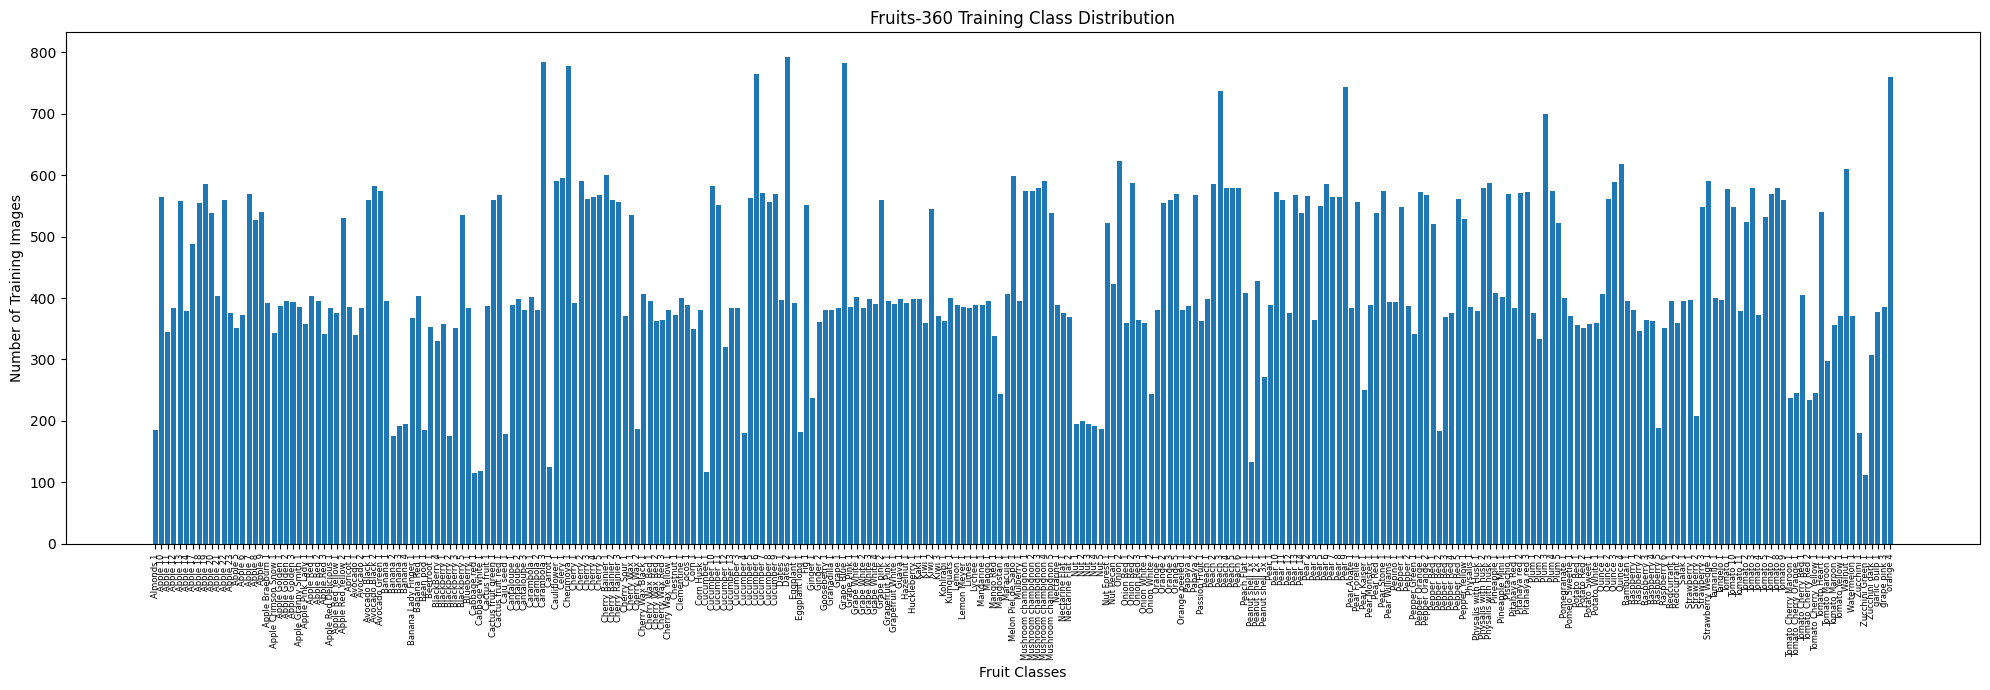

In [16]:
train_labels = get_labels(raw_train)

val_labels = get_labels(raw_val)

test_labels = get_labels(raw_test)

print("Training images  :", len(train_labels))

print("Validation images:", len(val_labels))

print("Testing images   :", len(test_labels))

print("Total images     :", len(train_labels) + len(val_labels) + len(test_labels))

# Table: how many images each class has in each split
class_distribution = pd.DataFrame({
    "Class": class_names,
    "Training Images": np.bincount(train_labels, minlength=NUM_CLASSES),
    "Validation Images": np.bincount(val_labels, minlength=NUM_CLASSES),
    "Testing Images": np.bincount(test_labels, minlength=NUM_CLASSES),
})

display(class_distribution)

class_distribution.to_csv(CSV_DIR / "task4_class_distribution.csv", index=False)

# Bar chart of the training images per class
plt.figure(figsize=(20, 7))

plt.bar(class_distribution["Class"], class_distribution["Training Images"])

plt.xticks(rotation=90, fontsize=6)

plt.xlabel("Fruit Classes")

plt.ylabel("Number of Training Images")

plt.title("Fruits-360 Training Class Distribution")

save_and_show(PLOTS_DIR / "task4_class_distribution.png")

In [17]:
def show_one_image_per_class(dataset, n_classes=20):
    """Show the first image found for each of `n_classes` different classes."""
    fig, axes = plt.subplots(4, 5, figsize=(15, 12))
    shown = set()
    for images, labels in dataset:
        for image, label in zip(images.numpy(), labels.numpy()):
            class_id = int(label)
            if class_id in shown:
                continue
            ax = axes.flat[len(shown)]
            ax.imshow(image.astype("uint8"))
            ax.set_title(class_names[class_id], fontsize=8)
            ax.axis("off")
            shown.add(class_id)
            if len(shown) == n_classes:
                plt.suptitle(f"One Image from {n_classes} Different Fruits-360 Classes", fontsize=16)
                save_and_show(PLOTS_DIR / "task4_20_fruit_classes.png")
                return

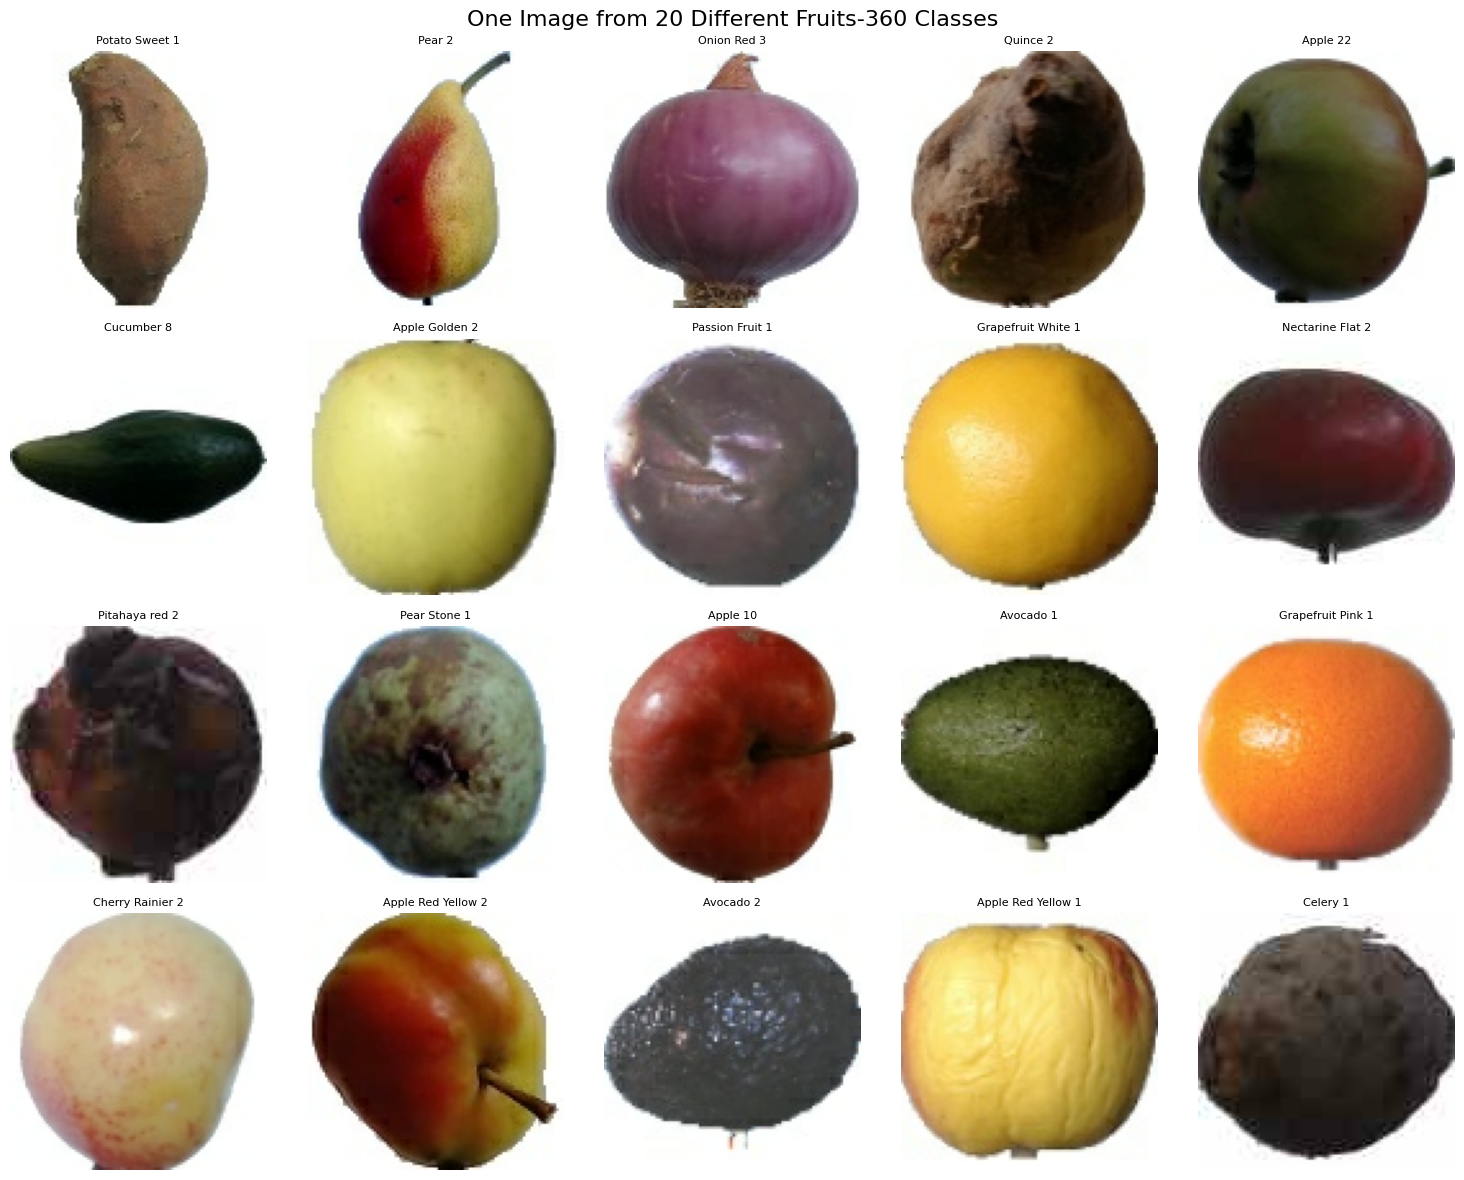

In [18]:
show_one_image_per_class(raw_train)

## SECTION 4 : RGB / GRAYSCALE / HSV VERSIONS OF THE DATA

> Pixel values are scaled from 0-255 to 0-1 first (neural networks train
> better on small numbers), then converted to the requested colour space.

In [19]:
def convert_colour_dataset(dataset, colour_space):
    """Return the dataset with images scaled to 0-1 and converted to
    "RGB", "Grayscale" or "HSV"."""
    def convert(images, labels):
        images = tf.cast(images, tf.float32) / 255.0
        if colour_space == "RGB":
            images = images
        elif colour_space == "Grayscale":
            images = tf.image.rgb_to_grayscale(images)
        elif colour_space == "HSV":
            images = tf.image.rgb_to_hsv(images)
        else:
            raise ValueError(f"Unsupported colour space: {colour_space}")
        return images, labels

    return dataset.map(convert, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

RGB, Grayscale and HSV datasets prepared.


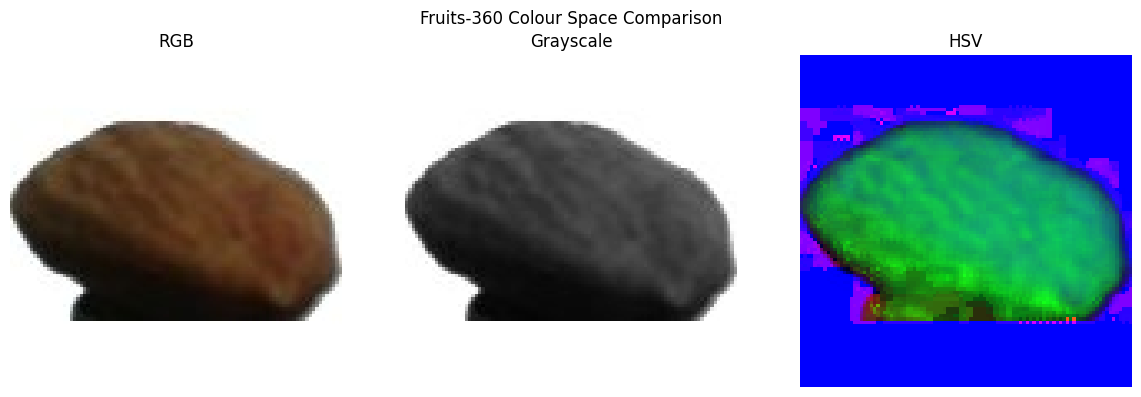

In [20]:
# colour_data["HSV"]["train"] is the HSV version of the training set, etc.
colour_data = {
    space: {
        "train": convert_colour_dataset(raw_train, space),
        "val": convert_colour_dataset(raw_val, space),
        "test": convert_colour_dataset(raw_test, space),
    }
    for space in COLOUR_SPACES
}

print("RGB, Grayscale and HSV datasets prepared.")

# Show one test image in the three colour spaces
sample_images, _ = next(iter(raw_test))

sample = tf.cast(sample_images[0], tf.float32) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(sample)

axes[0].set_title("RGB")

axes[1].imshow(tf.squeeze(tf.image.rgb_to_grayscale(sample)), cmap="gray")

axes[1].set_title("Grayscale")

axes[2].imshow(tf.image.rgb_to_hsv(sample))

axes[2].set_title("HSV")

for ax in axes:
    ax.axis("off")

plt.suptitle("Fruits-360 Colour Space Comparison")

save_and_show(PLOTS_DIR / "task4_colour_spaces.png")

## SECTION 5 : 4(b) THE CNN - ARCHITECTURE, PARAMETER COUNT, RGB TRAINING

In [21]:
def build_fruit_cnn(num_classes, input_channels=3, learning_rate=0.001, track_top5=True):
    """4 x (Conv 5x5 + MaxPool) -> Flatten -> Dense 1024 -> Dense 256 -> Softmax."""
    L = keras.layers
    model = keras.Sequential([
        L.Input(shape=(100, 100, input_channels)),
        L.Conv2D(16, (5, 5), activation="relu", padding="same", name="fruit_conv1"),
        L.MaxPooling2D((2, 2), strides=2, name="fruit_pool1"),
        L.Conv2D(32, (5, 5), activation="relu", padding="same", name="fruit_conv2"),
        L.MaxPooling2D((2, 2), strides=2, name="fruit_pool2"),
        L.Conv2D(64, (5, 5), activation="relu", padding="same", name="fruit_conv3"),
        L.MaxPooling2D((2, 2), strides=2, name="fruit_pool3"),
        L.Conv2D(128, (5, 5), activation="relu", padding="same", name="fruit_conv4"),
        L.MaxPooling2D((2, 2), strides=2, name="fruit_pool4"),
        L.Flatten(name="fruit_flatten"),
        L.Dense(1024, activation="relu", name="fruit_dense1024"),
        L.Dense(256, activation="relu", name="fruit_dense256"),
        L.Dense(num_classes, activation="softmax", name="fruit_predictions"),
    ], name=f"Fruits360_CNN_{num_classes}_classes")

    metrics = ["accuracy"]
    if track_top5:
        metrics.append(keras.metrics.SparseTopKCategoricalAccuracy(
            k=min(5, num_classes), name="top5_accuracy"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=metrics,
    )
    return model

In [22]:
def print_manual_parameter_count(num_classes):
    """Parameters by hand:
       Conv layer = (kernel_h * kernel_w * input_channels + 1 bias) * filters
       Dense layer = (inputs * outputs) + outputs (biases)"""
    # 100 -> 50 -> 25 -> 12 -> 6 after four poolings, with 128 filters: 6*6*128
    flatten_size = 6 * 6 * 128                      # = 4608

    layers = {
        "Conv 1": (5 * 5 * 3 + 1) * 16,
        "Conv 2": (5 * 5 * 16 + 1) * 32,
        "Conv 3": (5 * 5 * 32 + 1) * 64,
        "Conv 4": (5 * 5 * 64 + 1) * 128,
        "Dense 1024": flatten_size * 1024 + 1024,
        "Dense 256": 1024 * 256 + 256,
        "Output layer": 256 * num_classes + num_classes,
    }
    for name, count in layers.items():
        print(f"{name:13s}: {count:,}")
    print(f"{'TOTAL':13s}: {sum(layers.values()):,}")
    return sum(layers.values())

In [23]:
def print_pooling_shapes(model):
    """Push one blank image through the model layer by layer and print the
    output shape after every pooling layer and after Flatten."""
    x = tf.zeros((1, 100, 100, model.input_shape[-1]))
    for layer in model.layers:
        x = layer(x)
        if "pool" in layer.name or "flatten" in layer.name:
            print(f"After {layer.name:14s}: {tuple(x.shape[1:])}")

### Inspect the architecture (this model is only for inspection)

In [24]:
demo_model = build_fruit_cnn(NUM_CLASSES, input_channels=3)

demo_model.summary()

manual_total = print_manual_parameter_count(NUM_CLASSES)

print("Keras parameter count:", f"{demo_model.count_params():,}",
      "| matches manual count:", manual_total == demo_model.count_params())

print_pooling_shapes(demo_model)

Model: "Fruits360_CNN_278_classes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fruit_conv1 (Conv2D)            │ (None, 100, 100, 16)   │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool1 (MaxPooling2D)      │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_conv2 (Conv2D)            │ (None, 50, 50, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool2 (MaxPooling2D)      │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_conv3 (Conv2D)            │ (None, 25, 25, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool3 (MaxPooling2D)      │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_conv4 (Conv2D)            │ (None, 12, 12, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool4 (MaxPooling2D)      │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_flatten (Flatten)         │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_dense1024 (Dense)         │ (None, 1024)           │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_dense256 (Dense)          │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_predictions (Dense)       │ (None, 278)            │        71,446 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,323,702 (20.31 MB)

 Trainable params: 5,323,702 (20.31 MB)

 Non-trainable params: 0 (0.00 B)

Conv 1       : 1,216
Conv 2       : 12,832
Conv 3       : 51,264
Conv 4       : 204,928
Dense 1024   : 4,719,616
Dense 256    : 262,400
Output layer : 71,446
TOTAL        : 5,323,702
Keras parameter count: 5,323,702 | matches manual count: True
After fruit_pool1   : (50, 50, 16)
After fruit_pool2   : (25, 25, 32)
After fruit_pool3   : (12, 12, 64)
After fruit_pool4   : (6, 6, 128)
After fruit_flatten : (4608,)


### Train + evaluate helper (used for RGB, Grayscale and HSV)

In [25]:
def train_and_evaluate(space):
    """Build, train (with Drive checkpoints) and test one classifier."""
    data = colour_data[space]
    model = build_fruit_cnn(NUM_CLASSES, input_channels=COLOUR_SPACES[space])

    # NUM_CLASSES is part of the checkpoint name so an old checkpoint trained
    # with a different number of classes is never loaded by mistake.
    model, history, timer = train_with_checkpoints(
        name=f"{space.lower()}_classifier_{NUM_CLASSES}cls",
        model=model,
        train_ds=data["train"],
        val_ds=data["val"],
        epochs=EPOCHS,
    )

    test_metrics = model.evaluate(data["test"], verbose=1, return_dict=True)

    print(f"\n{space.upper()} CLASSIFIER RESULTS")
    print("Training Accuracy   :", history.history["accuracy"][-1])
    print("Validation Accuracy :", history.history["val_accuracy"][-1])
    print("Test Accuracy       :", test_metrics["accuracy"])
    print("Top-5 Test Accuracy :", test_metrics["top5_accuracy"])
    print("Avg Time Per Epoch  :", np.mean(timer.epoch_times))
    print("Total Parameters    :", model.count_params())

    return {"model": model, "history": history, "timer": timer, "test_metrics": test_metrics}

In [26]:
def plot_training_curves(history, title, save_path):
    """Accuracy curve (left) and loss curve (right), training vs validation."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, metric, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(history.history[metric], label=f"Training {label}")
        ax.plot(history.history[f"val_{metric}"], label=f"Validation {label}")
        ax.set_title(f"{title} {label}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.legend()
    save_and_show(save_path)

### Train the RGB classifier

[rgb_classifier_278cls] Loaded checkpoint from Drive: 25/25 epochs already done.
[rgb_classifier_278cls] Already trained for 25 epochs - skipping training.
996/996 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.9498 - loss: 2.9688 - top5_accuracy: 0.9872

RGB CLASSIFIER RESULTS
Training Accuracy   : 0.9926906228065491
Validation Accuracy : 0.99779212474823
Test Accuracy       : 0.9497841000556946
Top-5 Test Accuracy : 0.9872451424598694
Avg Time Per Epoch  : 53.170860328674316
Total Parameters    : 5323702


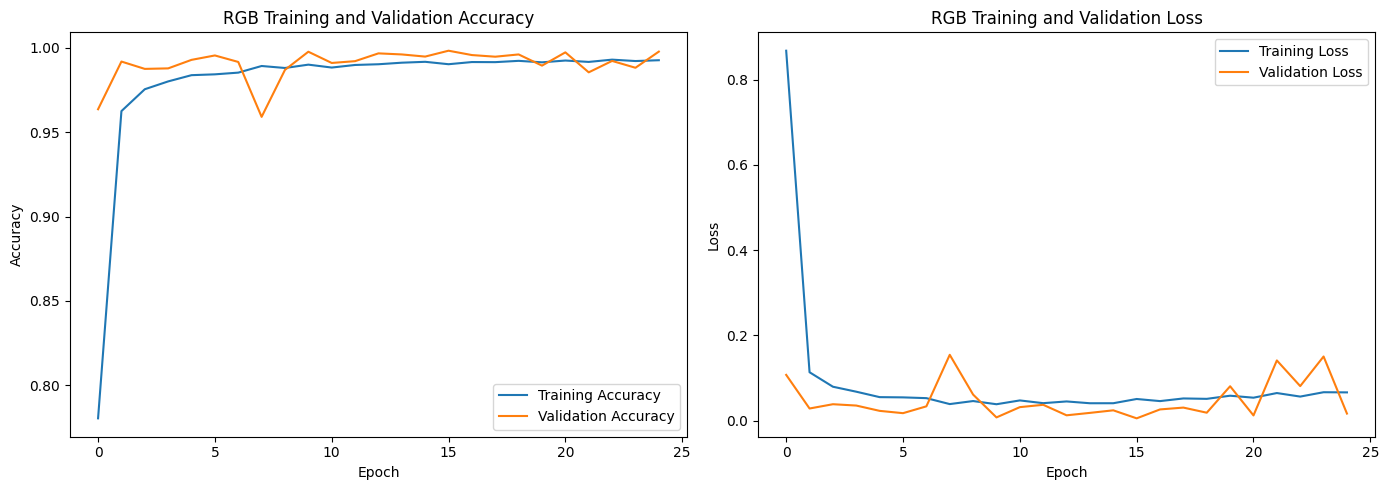

In [27]:
results = {}                                   # results["RGB"], results["HSV"], ...

results["RGB"] = train_and_evaluate("RGB")

plot_training_curves(results["RGB"]["history"], "RGB Training and Validation",
                     PLOTS_DIR / "task4_rgb_curves.png")

## SECTION 6 : 4(c) GRAYSCALE AND HSV CLASSIFIERS + COMPARISON WITH THE PAPER

[grayscale_classifier_278cls] Loaded checkpoint from Drive: 25/25 epochs already done.
[grayscale_classifier_278cls] Already trained for 25 epochs - skipping training.
996/996 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - accuracy: 0.9355 - loss: 2.5257 - top5_accuracy: 0.9752

GRAYSCALE CLASSIFIER RESULTS
Training Accuracy   : 0.9947479367256165
Validation Accuracy : 0.9946141242980957
Test Accuracy       : 0.9354825615882874
Top-5 Test Accuracy : 0.9751933217048645
Avg Time Per Epoch  : 59.32060382843017
Total Parameters    : 5322902
[hsv_classifier_278cls] Loaded checkpoint from Drive: 5/25 epochs already done.
Epoch 6/25
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9881 - loss: 0.0479 - top5_accuracy: 0.9996  -> checkpoint saved to Drive (epoch 6)
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 123s 46ms/step - accuracy: 0.9885 - loss: 0.0452 - top5_accuracy: 0.9997 - val_accuracy: 0.9898 - val_loss: 0.0402 - val_top5_accuracy: 0.9990
Epoch 7/25
2391/2392 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - acc

,Colour Space,Our Test Accuracy,Published Accuracy,Our Accuracy (%),Published Accuracy (%),Difference (Percentage Points)
0,RGB,0.950,0.987,94.978,98.66,-3.682
1,Grayscale,0.935,0.952,93.548,95.25,-1.702
2,HSV,0.954,0.961,95.432,96.09,-0.658


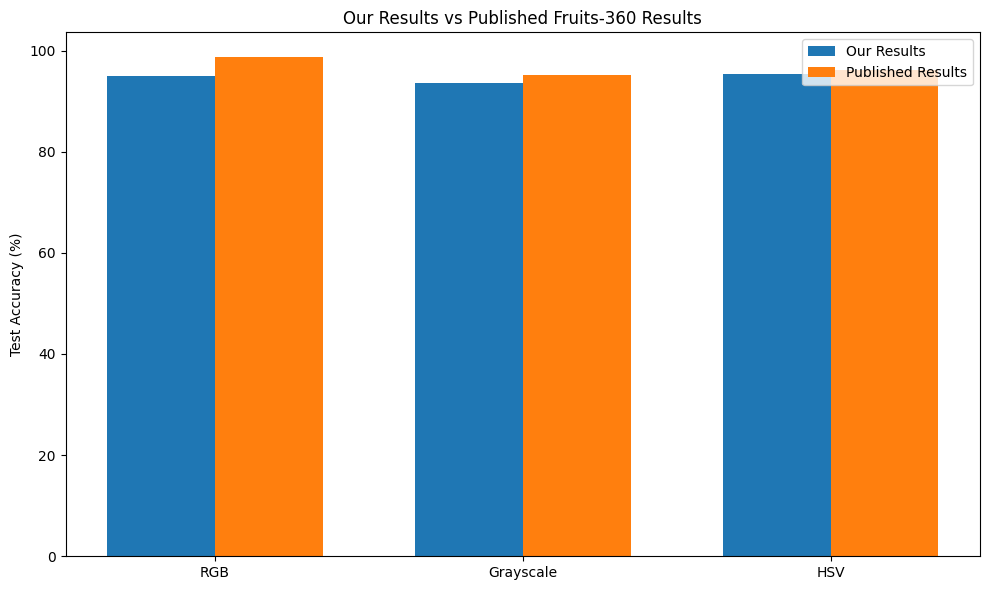

In [28]:
results["Grayscale"] = train_and_evaluate("Grayscale")
results["HSV"] = train_and_evaluate("HSV")

colour_comparison = pd.DataFrame({
    "Colour Space": list(COLOUR_SPACES),
    "Our Test Accuracy": [results[s]["test_metrics"]["accuracy"] for s in COLOUR_SPACES],
    "Published Accuracy": [PUBLISHED_ACCURACY[s] for s in COLOUR_SPACES],
})

colour_comparison["Our Accuracy (%)"] = colour_comparison["Our Test Accuracy"] * 100
colour_comparison["Published Accuracy (%)"] = colour_comparison["Published Accuracy"] * 100
colour_comparison["Difference (Percentage Points)"] = (
    colour_comparison["Our Accuracy (%)"] - colour_comparison["Published Accuracy (%)"]
)

display(colour_comparison.round(3))
colour_comparison.to_csv(CSV_DIR / "task4_colour_comparison.csv", index=False)

# Bar chart: our results vs published results
x = np.arange(len(COLOUR_SPACES))
width = 0.35
plt.figure(figsize=(10, 6))
plt.bar(x - width / 2, colour_comparison["Our Accuracy (%)"], width, label="Our Results")
plt.bar(x + width / 2, colour_comparison["Published Accuracy (%)"], width, label="Published Results")
plt.xticks(x, colour_comparison["Colour Space"])
plt.ylabel("Test Accuracy (%)")
plt.title("Our Results vs Published Fruits-360 Results")
plt.legend()

save_and_show(PLOTS_DIR / "task4_published_comparison.png")

## SECTION 7 : 4(c) CONFUSION MATRIX FOR THE APPLE CLASSES

Number of apple classes: 30
Apple 10
Apple 11
Apple 12
Apple 13
Apple 14
Apple 17
Apple 18
Apple 19
Apple 20
Apple 21
Apple 22
Apple 23
Apple 5
Apple 6
Apple 7
Apple 8
Apple 9
Apple Braeburn 1
Apple Crimson Snow 1
Apple Golden 1
Apple Golden 2
Apple Golden 3
Apple Granny Smith 1
Apple Pink Lady 1
Apple Red 1
Apple Red 2
Apple Red 3
Apple Red Delicious 1
Apple Red Yellow 1
Apple Red Yellow 2
996/996 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step
Actual apple test images: 5506
Apple images predicted as non-apple: 140


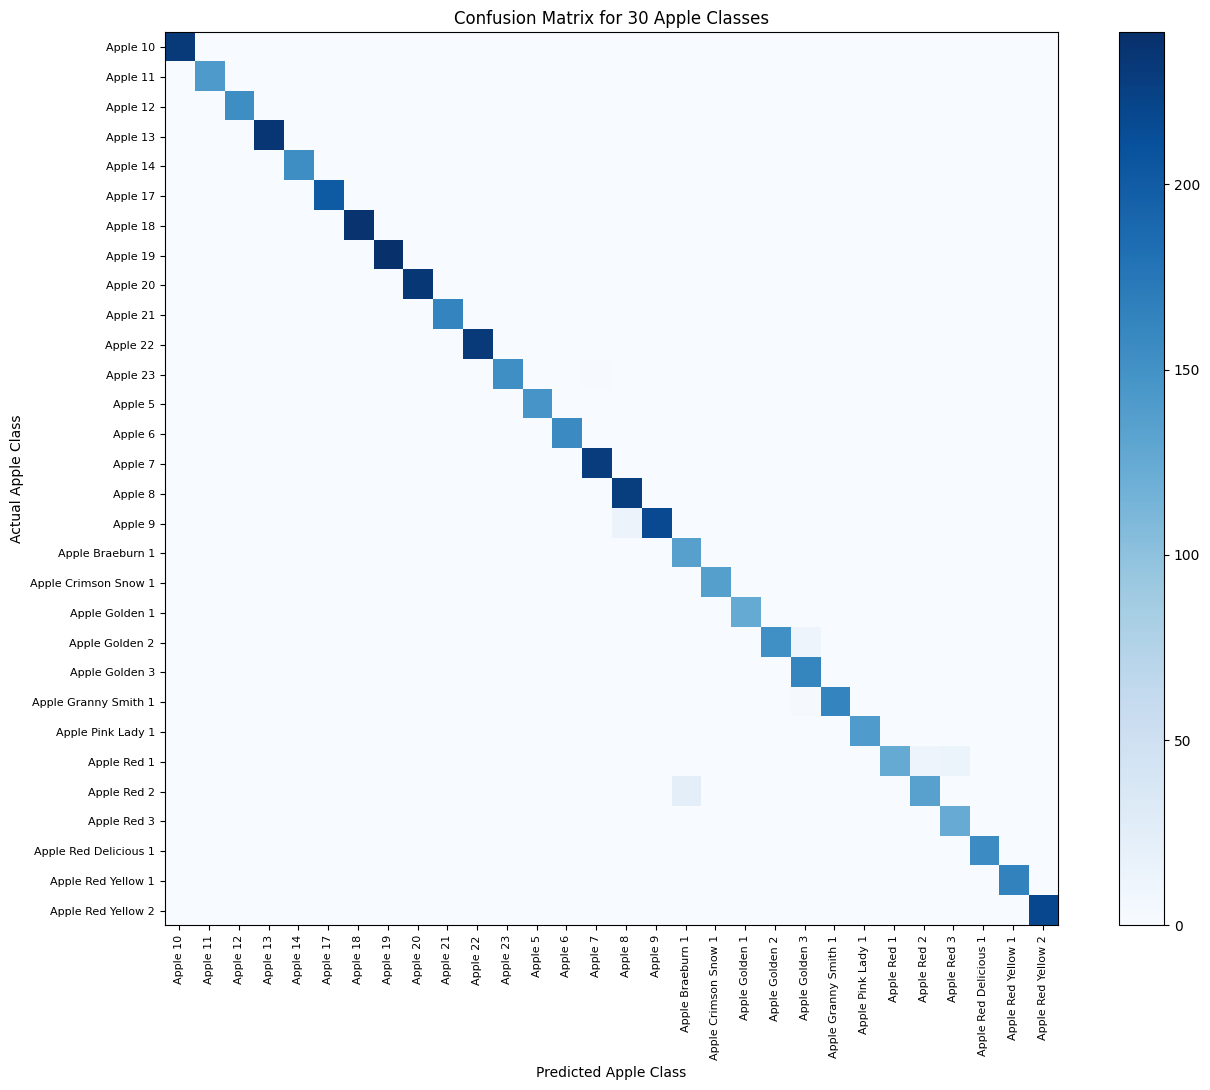

In [29]:
# Classes whose name starts with "apple" (this skips e.g. "Pineapple").
apple_class_ids = [i for i, name in enumerate(class_names) if name.lower().startswith("apple")]
apple_class_names = [class_names[i] for i in apple_class_ids]
print(f"Number of apple classes: {len(apple_class_ids)}")
print("\n".join(apple_class_names))

# Predict on the whole test set (test data is not shuffled, so order matches)
rgb_model = results["RGB"]["model"]
y_true = get_labels(colour_data["RGB"]["test"])
y_pred = np.argmax(rgb_model.predict(colour_data["RGB"]["test"], verbose=1), axis=1)

# Keep only the images whose TRUE class is an apple
apple_mask = np.isin(y_true, apple_class_ids)
apple_true = y_true[apple_mask]
apple_pred = y_pred[apple_mask]
print("Actual apple test images:", len(apple_true))
print("Apple images predicted as non-apple:", np.sum(~np.isin(apple_pred, apple_class_ids)))
apple_cm = confusion_matrix(apple_true, apple_pred, labels=apple_class_ids)
plt.figure(figsize=(14, 11))
plt.imshow(apple_cm, interpolation="nearest", cmap="Blues")

plt.colorbar()
plt.xticks(np.arange(len(apple_class_names)), apple_class_names, rotation=90, fontsize=8)
plt.yticks(np.arange(len(apple_class_names)), apple_class_names, fontsize=8)
plt.xlabel("Predicted Apple Class")
plt.ylabel("Actual Apple Class")
plt.title(f"Confusion Matrix for {len(apple_class_ids)} Apple Classes")

save_and_show(PLOTS_DIR / "task4_apple_confusion_matrix.png")
np.savetxt(CSV_DIR / "task4_apple_confusion_matrix.csv", apple_cm, delimiter=",", fmt="%d")

## SECTION 8 : 4(d) FRUIT DETECTION

> 8.1  Make multi-fruit scenes (several fruits pasted on a white canvas)
> 8.2  Make "background" patches so the CNN can learn "this is NOT a fruit"
> 8.3  Build + train a detector = the CNN with one extra output class
> 8.4  Sliding window + Non-Maximum Suppression
> 8.5  Measure precision / recall / F1 for different strides and thresholds

### 8.1  Multi-fruit scenes

In [30]:
@lru_cache(maxsize=None)
def get_image_files(class_dir):
    """All image files inside one class folder (cached, so it is fast)."""
    return tuple(sorted(
        p for p in Path(class_dir).iterdir()
        if p.is_file() and p.suffix.lower() in (".jpg", ".jpeg", ".png")
    ))

In [31]:
@lru_cache(maxsize=None)
def list_class_dirs(root):
    """All class folders inside Training/ or Test/ that contain images."""
    return tuple(sorted(
        p for p in Path(root).iterdir() if p.is_dir() and get_image_files(p)
    ))

In [32]:
def overlaps_any(x, y, boxes):
    """Would a fruit placed at (x, y) overlap one of the existing boxes?"""
    return any(
        not (x + FRUIT_SIZE <= bx1 or bx2 <= x or y + FRUIT_SIZE <= by1 or by2 <= y)
        for bx1, by1, bx2, by2 in boxes
    )

In [33]:
def make_scene(test_dir, n_fruits=4, size=SCENE_SIZE, seed=None):
    """Paste `n_fruits` random fruit images on a white canvas without overlap.
    Returns (scene image, ground-truth boxes, ground-truth class names)."""
    rng = random.Random(seed)
    class_dirs = list_class_dirs(str(test_dir))
    canvas = Image.new("RGB", size, (255, 255, 255))
    boxes, labels = [], []

    attempts = 0
    while len(boxes) < n_fruits and attempts < 5000:
        attempts += 1
        class_dir = rng.choice(class_dirs)
        image_path = rng.choice(get_image_files(class_dir))
        x = rng.randint(0, size[0] - FRUIT_SIZE)
        y = rng.randint(0, size[1] - FRUIT_SIZE)

        if overlaps_any(x, y, boxes):
            continue

        fruit = Image.open(image_path).convert("RGB").resize((FRUIT_SIZE, FRUIT_SIZE))
        canvas.paste(fruit, (x, y))
        boxes.append((x, y, x + FRUIT_SIZE, y + FRUIT_SIZE))
        labels.append(class_dir.name)

    if len(boxes) != n_fruits:
        raise RuntimeError("Could not place all fruits without overlap.")
    return np.array(canvas), boxes, labels

In [34]:
def draw_boxes(ax, boxes, labels, color, prefix="", linestyle="-",
               text_above=True, text_background=None):
    """Draw rectangles with a text label on a matplotlib axis."""
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2,
                               edgecolor=color, facecolor="none", linestyle=linestyle))
        ax.text(x1, y1 - 5 if text_above else y2 + 10, prefix + label,
                color=color, fontsize=8, backgroundcolor=text_background)

Total generated scenes: 50
First scene shape     : (350, 500, 3)
First scene labels    : ['Cantaloupe 1', 'Kiwi 3', 'Cabbage white 1', 'Beetroot 1']


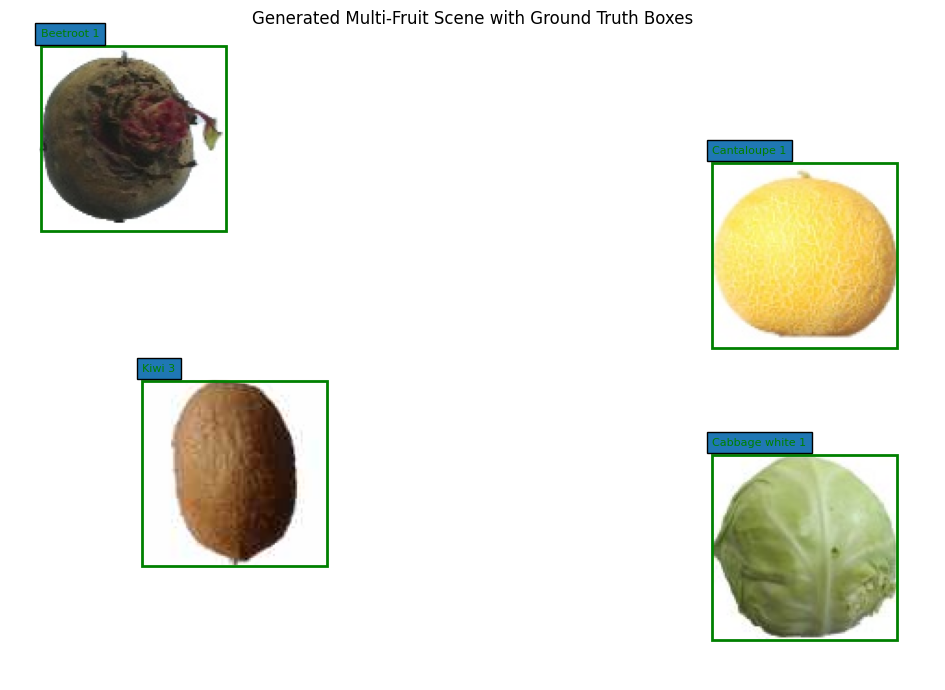

In [35]:
detection_scenes = [
    make_scene(TEST_DIR, n_fruits=random.choice([3, 4, 5]), seed=SEED + i)
    for i in range(DETECTION_SCENE_COUNT)
]

print("Total generated scenes:", len(detection_scenes))

print("First scene shape     :", detection_scenes[0][0].shape)

print("First scene labels    :", detection_scenes[0][2])

# Look at one scene with its ground-truth boxes
scene, gt_boxes, gt_labels = detection_scenes[0]

fig, ax = plt.subplots(figsize=(12, 7))

ax.imshow(scene)

draw_boxes(ax, gt_boxes, gt_labels, color="green")

ax.set_title("Generated Multi-Fruit Scene with Ground Truth Boxes")

ax.axis("off")

plt.tight_layout()

plt.show()

### 8.2  Background class (the extra, 121st class)

In [36]:
def make_background_patches(train_dir, n_empty=500, n_partial=500, seed=SEED):
    """Create 100x100 patches that are NOT a complete fruit:
       * empty patches  : plain white
       * partial patches: a fruit pushed mostly out of the window"""
    rng = random.Random(seed)
    class_dirs = list_class_dirs(str(train_dir))
    patches = [np.full((100, 100, 3), 255, dtype=np.uint8) for _ in range(n_empty)]

    for _ in range(n_partial):
        image_path = rng.choice(get_image_files(rng.choice(class_dirs)))
        fruit = Image.open(image_path).convert("RGB").resize((100, 100))
        patch = Image.new("RGB", (100, 100), (255, 255, 255))

        dx = rng.randint(-75, 75)
        dy = rng.randint(-75, 75)
        if dx == 0 and dy == 0:
            dx = 20                       # make sure the fruit is really shifted
        patch.paste(fruit, (dx, dy))
        patches.append(np.asarray(patch, dtype=np.uint8))

    rng.shuffle(patches)
    return np.stack(patches)

Background patches: 1000 | background class id: 278 | detector classes: 279


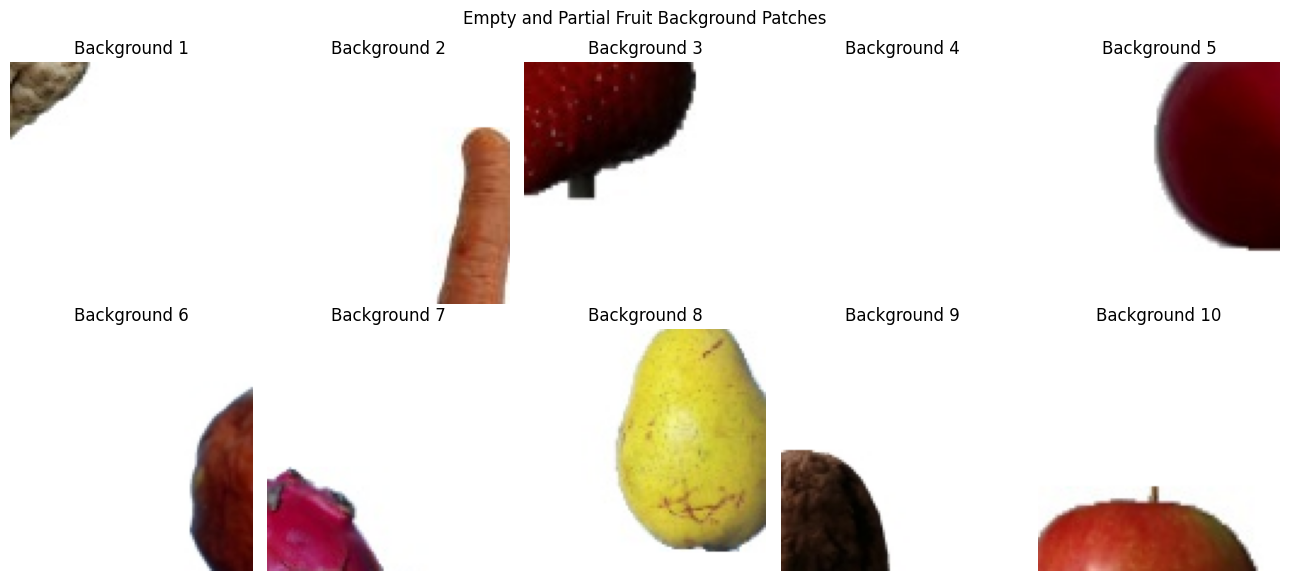

In [37]:
background_patches = make_background_patches(TRAIN_DIR, n_empty=500, n_partial=500)

print("Background patches:", len(background_patches),
      "| background class id:", BACKGROUND_LABEL,
      "| detector classes:", NUM_CLASSES + 1)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(background_patches[i])
    ax.set_title(f"Background {i + 1}")
    ax.axis("off")

plt.suptitle("Empty and Partial Fruit Background Patches")

plt.tight_layout()

plt.show()

# Shuffle, then 800 patches for training and 200 for validation
order = np.random.default_rng(SEED).permutation(len(background_patches))

background_patches = background_patches[order]

bg_train, bg_val = background_patches[:800], background_patches[800:]

In [38]:
def make_background_dataset(patches):
    """Turn background patches into a tf.data dataset labelled as background."""
    labels = np.full(len(patches), BACKGROUND_LABEL, dtype=np.int32)
    return tf.data.Dataset.from_tensor_slices((patches.astype("float32") / 255.0, labels))

In [39]:
# Detector data = normal fruit images + background patches
rgb_train, rgb_val = colour_data["RGB"]["train"], colour_data["RGB"]["val"]

detector_train_dataset = (
    rgb_train.unbatch()
    .concatenate(make_background_dataset(bg_train))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

detector_val_dataset = (
    rgb_val.unbatch()
    .concatenate(make_background_dataset(bg_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Detector datasets prepared.")

Detector datasets prepared.


### 8.3  Build and train the detector

In [40]:
def transfer_weights(source_model, target_model):
    """Copy the weights of every layer except the last one (the output layer
    has a different size). The detector therefore starts from the already
    trained RGB classifier instead of from scratch."""
    for old_layer, new_layer in zip(source_model.layers[:-1], target_model.layers[:-1]):
        if old_layer.get_weights():
            new_layer.set_weights(old_layer.get_weights())

Model: "Fruits360_CNN_279_classes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fruit_conv1 (Conv2D)            │ (None, 100, 100, 16)   │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool1 (MaxPooling2D)      │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_conv2 (Conv2D)            │ (None, 50, 50, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool2 (MaxPooling2D)      │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_conv3 (Conv2D)            │ (None, 25, 25, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool3 (MaxPooling2D)      │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_conv4 (Conv2D)            │ (None, 12, 12, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_pool4 (MaxPooling2D)      │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_flatten (Flatten)         │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_dense1024 (Dense)         │ (None, 1024)           │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_dense256 (Dense)          │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fruit_predictions (Dense)       │ (None, 279)            │        71,703 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,323,959 (20.31 MB)

 Trainable params: 5,323,959 (20.31 MB)

 Non-trainable params: 0 (0.00 B)

[detector_279_class] No checkpoint found - training from scratch.
Epoch 1/10
   2408/Unknown 60s 22ms/step - accuracy: 0.1477 - loss: 7.1833

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  -> checkpoint saved to Drive (epoch 1)
2408/2408 ━━━━━━━━━━━━━━━━━━━━ 69s 26ms/step - accuracy: 0.4135 - loss: 3.6004 - val_accuracy: 0.9185 - val_loss: 0.3258
Epoch 2/10
2405/2408 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9472 - loss: 0.1944  -> checkpoint saved to Drive (epoch 2)
2408/2408 ━━━━━━━━━━━━━━━━━━━━ 59s 23ms/step - accuracy: 0.9675 - loss: 0.1239 - val_accuracy: 0.9893 - val_loss: 0.0454
Epoch 3/10
2408/2408 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9935 - loss: 0.0250  -> checkpoint saved to Drive (epoch 3)
2408/2408 ━━━━━━━━━━━━━━━━━━━━ 59s 23ms/step - accuracy: 0.9947 - loss: 0.0213 - val_accuracy: 0.9969 - val_loss: 0.0150
Epoch 4/10
2406/2408 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9971 - loss: 0.0096  -> checkpoint saved to Drive (epoch 4)
2408/2408 ━━━━━━━━━━━━━━━━━━━━ 82s 24ms/step - accuracy: 0.9975 - loss: 0.0084 - val_accuracy: 0.9977 - val_loss: 0.0108
Epoch 5/10
2406/2408 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9978 - loss: 0.0069

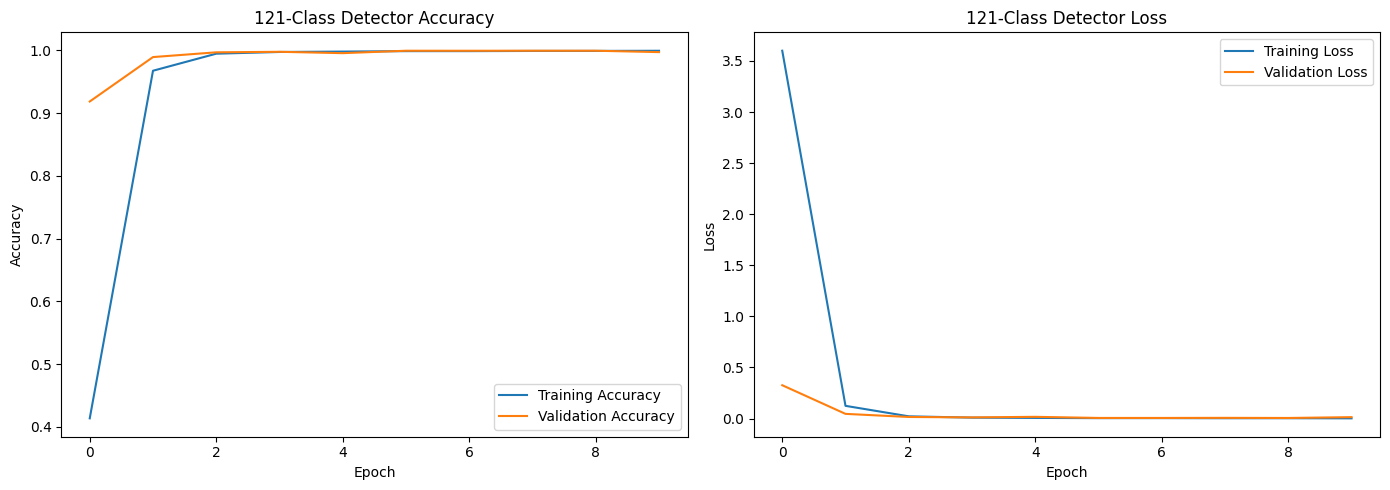

In [41]:
fruit_detector = build_fruit_cnn(
    NUM_CLASSES + 1, input_channels=3,
    learning_rate=0.0001,            # small learning rate: we only fine-tune
    track_top5=False,
)

transfer_weights(results["RGB"]["model"], fruit_detector)

fruit_detector.summary()

fruit_detector, detector_history, detector_timer = train_with_checkpoints(
    name=f"detector_{NUM_CLASSES + 1}_class",
    model=fruit_detector,
    train_ds=detector_train_dataset,
    val_ds=detector_val_dataset,
    epochs=DETECTOR_EPOCHS,
)

plot_training_curves(detector_history, "121-Class Detector",
                     PLOTS_DIR / "task4_detector_training.png")

### 8.4  Sliding window + Non-Maximum Suppression

In [42]:
def get_window_positions(length, window_size, stride):
    """Start positions of the windows along one axis. The last window is
    always placed exactly at the edge so no pixels are skipped."""
    positions = list(range(0, length - window_size + 1, stride))
    last_position = length - window_size
    if positions[-1] != last_position:
        positions.append(last_position)
    return positions

In [43]:
def predict_scene_windows(scene, model, stride=20):
    """Cut the scene into 100x100 windows, classify all of them.
    Returns (boxes, predicted classes, confidences, seconds taken)."""
    start_time = time.perf_counter()
    height, width, _ = scene.shape

    windows, boxes = [], []
    for y in get_window_positions(height, FRUIT_SIZE, stride):
        for x in get_window_positions(width, FRUIT_SIZE, stride):
            windows.append(scene[y:y + FRUIT_SIZE, x:x + FRUIT_SIZE])
            boxes.append((x, y, x + FRUIT_SIZE, y + FRUIT_SIZE))

    windows = np.asarray(windows, dtype=np.float32) / 255.0
    probabilities = model.predict(windows, batch_size=128, verbose=0)

    return (
        np.asarray(boxes),
        np.argmax(probabilities, axis=1),       # which class each window looks like
        np.max(probabilities, axis=1),          # how sure the model is
        time.perf_counter() - start_time,
    )

In [44]:
def apply_nms(boxes, classes, scores, probability_threshold=0.9):
    """Non-Maximum Suppression.
    1) drop background windows and windows with low confidence
    2) for each fruit class, merge heavily overlapping boxes into the best one"""
    detections = []
    valid = np.where((classes != BACKGROUND_LABEL) & (scores >= probability_threshold))[0]
    if len(valid) == 0:
        return detections

    for class_id in np.unique(classes[valid]):
        idx = valid[classes[valid] == class_id]

        # TensorFlow's NMS wants boxes as (y1, x1, y2, x2)
        yxyx = boxes[idx][:, [1, 0, 3, 2]].astype(np.float32)
        keep = tf.image.non_max_suppression(
            boxes=yxyx, scores=scores[idx], max_output_size=100, iou_threshold=NMS_IOU
        ).numpy()

        for k in keep:
            i = idx[k]
            detections.append({
                "box": boxes[i].tolist(),
                "class_id": int(classes[i]),
                "score": float(scores[i]),
            })

    detections.sort(key=lambda d: d["score"], reverse=True)
    return detections

In [45]:
# Try it on one scene
scene, gt_boxes, gt_labels = detection_scenes[0]

window_boxes, window_classes, window_scores, inference_time = predict_scene_windows(
    scene, fruit_detector, stride=20)

predicted_detections = apply_nms(window_boxes, window_classes, window_scores, 0.9)

print("Total sliding windows:", len(window_boxes))

print("Predicted detections :", len(predicted_detections))

print("Ground truth fruits  :", len(gt_boxes))

print("Inference time (s)   :", inference_time)

for d in predicted_detections:
    print("Class:", class_names[d["class_id"]], "| Confidence:", round(d["score"], 4),
          "| Box:", d["box"])

Total sliding windows: 294
Predicted detections : 12
Ground truth fruits  : 4
Inference time (s)   : 6.633316149000166
Class: Cherry Rainier 2 | Confidence: 0.9952 | Box: [400, 220, 500, 320]
Class: Physalis with Husk 1 | Confidence: 0.9944 | Box: [360, 240, 460, 340]
Class: Ginger 1 | Confidence: 0.9941 | Box: [380, 250, 480, 350]
Class: Carambola 1 | Confidence: 0.9929 | Box: [360, 100, 460, 200]
Class: Hazelnut 1 | Confidence: 0.989 | Box: [360, 60, 460, 160]
Class: Pineapple Mini 1 | Confidence: 0.977 | Box: [80, 180, 180, 280]
Class: Cauliflower 1 | Confidence: 0.9504 | Box: [20, 0, 120, 100]
Class: Peanut shell 2x 1 | Confidence: 0.9464 | Box: [80, 160, 180, 260]
Class: Pepper 2 | Confidence: 0.9417 | Box: [80, 220, 180, 320]
Class: Banana 3 | Confidence: 0.9178 | Box: [80, 120, 180, 220]
Class: Ginger 2 | Confidence: 0.9132 | Box: [360, 220, 460, 320]
Class: Banana Red 1 | Confidence: 0.9073 | Box: [400, 250, 500, 350]


### 8.5  Measuring detection quality

In [46]:
def calculate_iou(box1, box2):
    """Intersection over Union: how much two boxes overlap (0 = none, 1 = identical)."""
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    return intersection / union if union else 0.0

In [47]:
def evaluate_one_scene(detections, gt_boxes, gt_labels):
    """Count for one scene:
       TP = detection with the right class that overlaps a real fruit (IoU >= 0.5)
       FP = detection that matches nothing
       FN = real fruit that no detection found"""
    matched = set()
    tp = fp = 0

    for det in sorted(detections, key=lambda d: d["score"], reverse=True):
        best_iou, best_gt = 0, None
        for gt_index, (gt_box, gt_label) in enumerate(zip(gt_boxes, gt_labels)):
            if gt_index in matched or CLASS_TO_ID[gt_label] != det["class_id"]:
                continue
            iou = calculate_iou(det["box"], gt_box)
            if iou > best_iou:
                best_iou, best_gt = iou, gt_index

        if best_iou >= IOU_MATCH:
            tp += 1
            matched.add(best_gt)
        else:
            fp += 1

    fn = len(gt_boxes) - len(matched)
    return tp, fp, fn

In [48]:
def calculate_detection_metrics(tp, fp, fn):
    """Precision = TP/(TP+FP), Recall = TP/(TP+FN), F1 = their harmonic mean."""
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
    return precision, recall, f1

In [49]:
def run_detection_experiments(model, scenes, strides, thresholds):
    """Run every (stride, threshold) combination on every scene and return
    one results table."""
    stats = {(s, t): {"TP": 0, "FP": 0, "FN": 0, "Times": []}
             for s in strides for t in thresholds}

    for scene_number, (scene, gt_boxes, gt_labels) in enumerate(scenes, start=1):
        print(f"Processing scene {scene_number}/{len(scenes)}")
        for stride in strides:
            # The expensive part (running the CNN) is done once per stride...
            boxes, classes, scores, inference_time = predict_scene_windows(scene, model, stride)
            # ...and re-used for every threshold.
            for threshold in thresholds:
                start = time.perf_counter()
                detections = apply_nms(boxes, classes, scores, threshold)
                tp, fp, fn = evaluate_one_scene(detections, gt_boxes, gt_labels)
                post_time = time.perf_counter() - start

                entry = stats[(stride, threshold)]
                entry["TP"] += tp
                entry["FP"] += fp
                entry["FN"] += fn
                entry["Times"].append(inference_time + post_time)

    rows = []
    for (stride, threshold), v in stats.items():
        precision, recall, f1 = calculate_detection_metrics(v["TP"], v["FP"], v["FN"])
        rows.append({
            "Stride": stride,
            "Probability Threshold": threshold,
            "True Positives": v["TP"],
            "False Positives": v["FP"],
            "False Negatives": v["FN"],
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "Average Time Per Scene (seconds)": np.mean(v["Times"]),
        })
    return pd.DataFrame(rows)

In [56]:
import re

def normalize_label(label):
    return re.sub(r"\s+\d+$", "", str(label)).strip()   # "Blackberry 4" -> "Blackberry"

class LabelMap(dict):
    """Falls back to the base class name when an exact label isn't found."""
    def __missing__(self, key):
        base = normalize_label(key)
        if base in self:
            return self[base]
        raise KeyError(key)

# Add base-name keys alongside the existing ones (keeps the same class IDs)
CLASS_TO_ID = LabelMap({**CLASS_TO_ID, **{normalize_label(k): v for k, v in CLASS_TO_ID.items()}})

detection_results_df = run_detection_experiments(
    fruit_detector, detection_scenes, STRIDES, THRESHOLDS)

detection_results_df.to_csv(CSV_DIR / "task4_detection_comparison.csv", index=False)
display(detection_results_df.round(4))

Processing scene 1/50
Processing scene 2/50
Processing scene 3/50
Processing scene 4/50
Processing scene 5/50
Processing scene 6/50
Processing scene 7/50
Processing scene 8/50
Processing scene 9/50
Processing scene 10/50
Processing scene 11/50
Processing scene 12/50
Processing scene 13/50
Processing scene 14/50
Processing scene 15/50
Processing scene 16/50
Processing scene 17/50
Processing scene 18/50
Processing scene 19/50
Processing scene 20/50
Processing scene 21/50
Processing scene 22/50
Processing scene 23/50
Processing scene 24/50
Processing scene 25/50
Processing scene 26/50
Processing scene 27/50
Processing scene 28/50
Processing scene 29/50
Processing scene 30/50
Processing scene 31/50
Processing scene 32/50
Processing scene 33/50
Processing scene 34/50
Processing scene 35/50
Processing scene 36/50
Processing scene 37/50
Processing scene 38/50
Processing scene 39/50
Processing scene 40/50
Processing scene 41/50
Processing scene 42/50
Processing scene 43/50
Processing scene 44/

,Stride,Probability Threshold,True Positives,False Positives,False Negatives,Precision,Recall,F1 Score,Average Time Per Scene (seconds)
0,10,0.5,192,2952,7,0.0611,0.9648,0.1149,0.7330
1,10,0.7,191,2309,8,0.0764,0.9598,0.1415,0.7190
2,10,0.9,183,1519,16,0.1075,0.9196,0.1925,0.7024
3,20,0.5,150,1217,49,0.1097,0.7538,0.1916,0.2981
4,20,0.7,145,960,54,0.1312,0.7286,0.2224,0.2919
5,20,0.9,129,603,70,0.1762,0.6482,0.2771,0.2828
6,40,0.5,64,400,135,0.1379,0.3216,0.1931,0.1282
7,40,0.7,60,316,139,0.1596,0.3015,0.2087,0.1250
8,40,0.9,56,191,143,0.2267,0.2814,0.2511,0.1214


In [52]:
def plot_by_stride(df, column, ylabel, title, save_path):
    """One line per stride, x-axis = probability threshold."""
    plt.figure(figsize=(8, 5))
    for stride in STRIDES:
        subset = df[df["Stride"] == stride]
        plt.plot(subset["Probability Threshold"], subset[column],
                 marker="o", label=f"Stride {stride}")
    plt.xlabel("Probability Threshold")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    save_and_show(save_path)

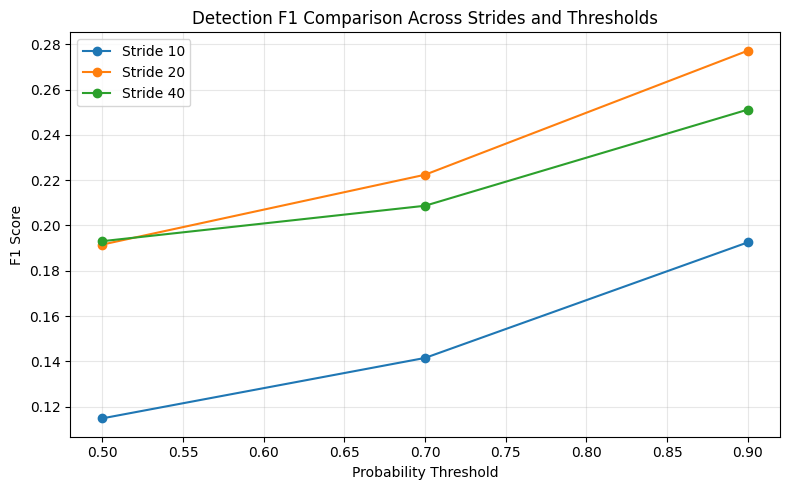

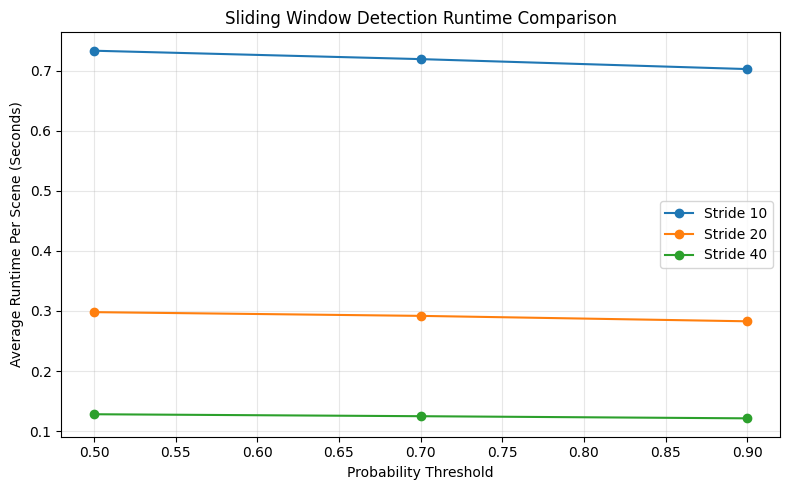

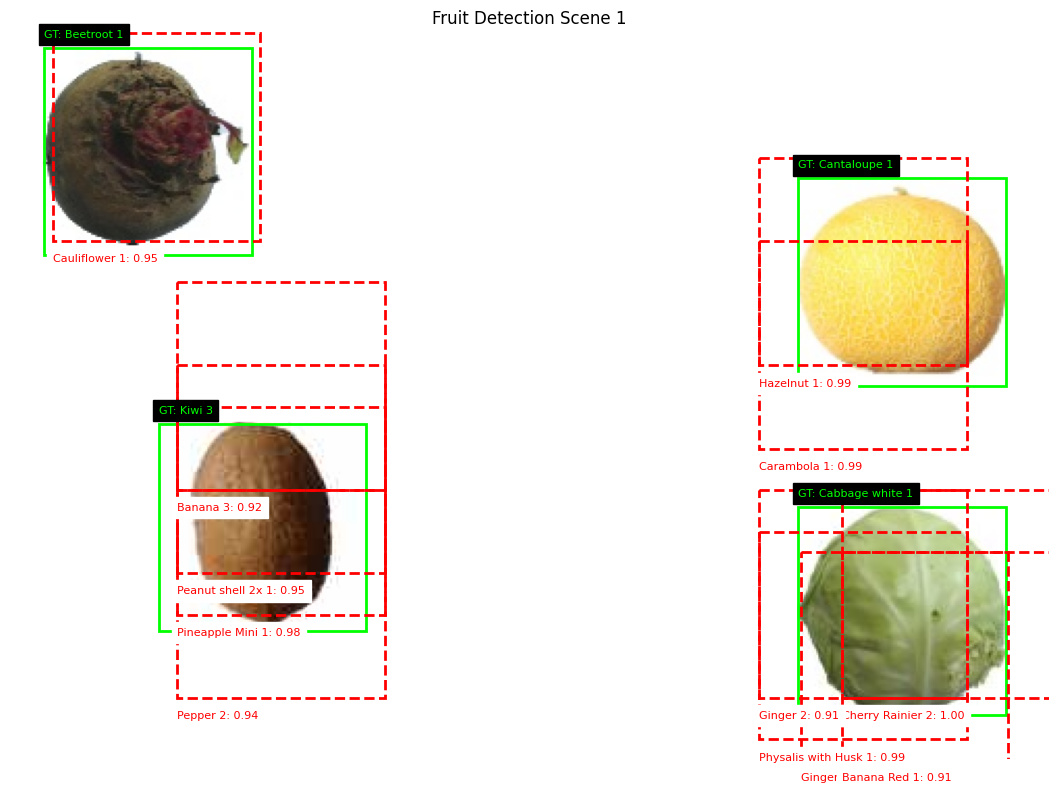

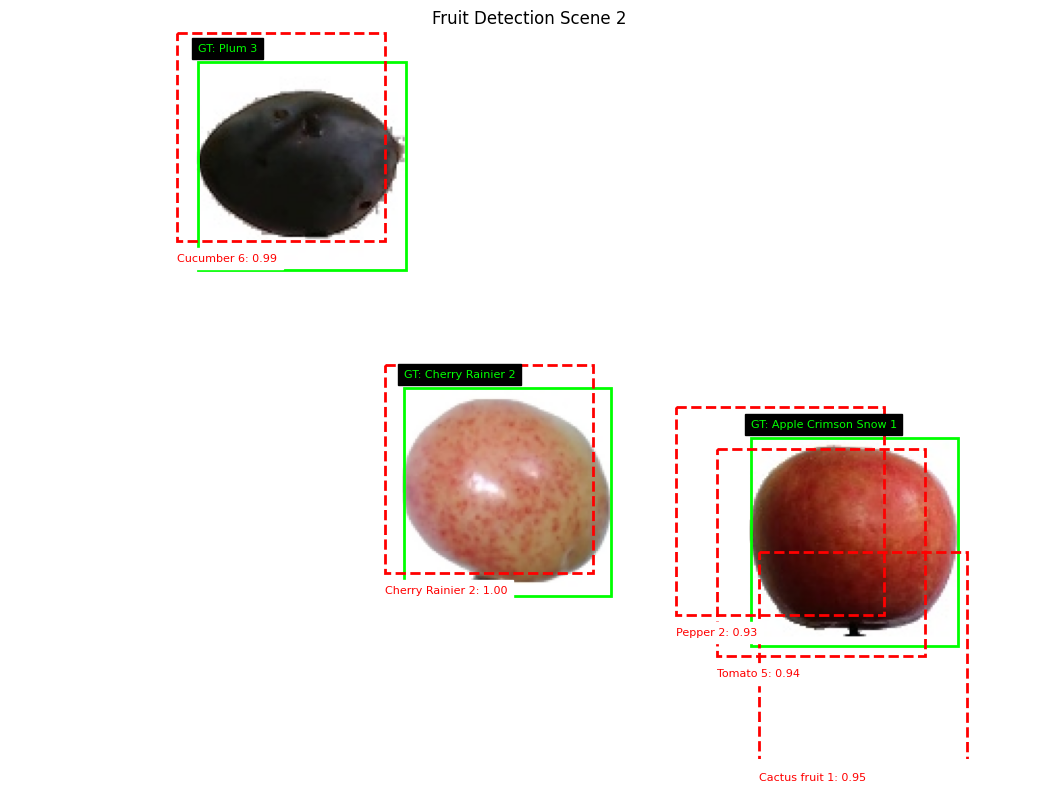

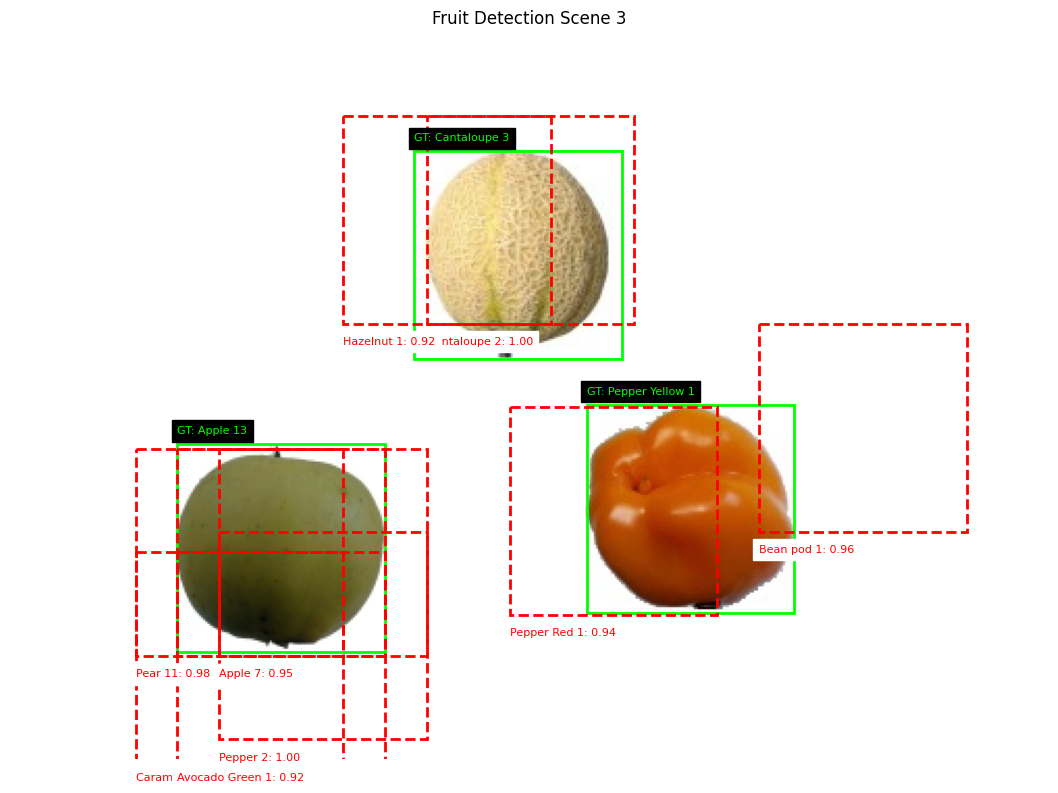

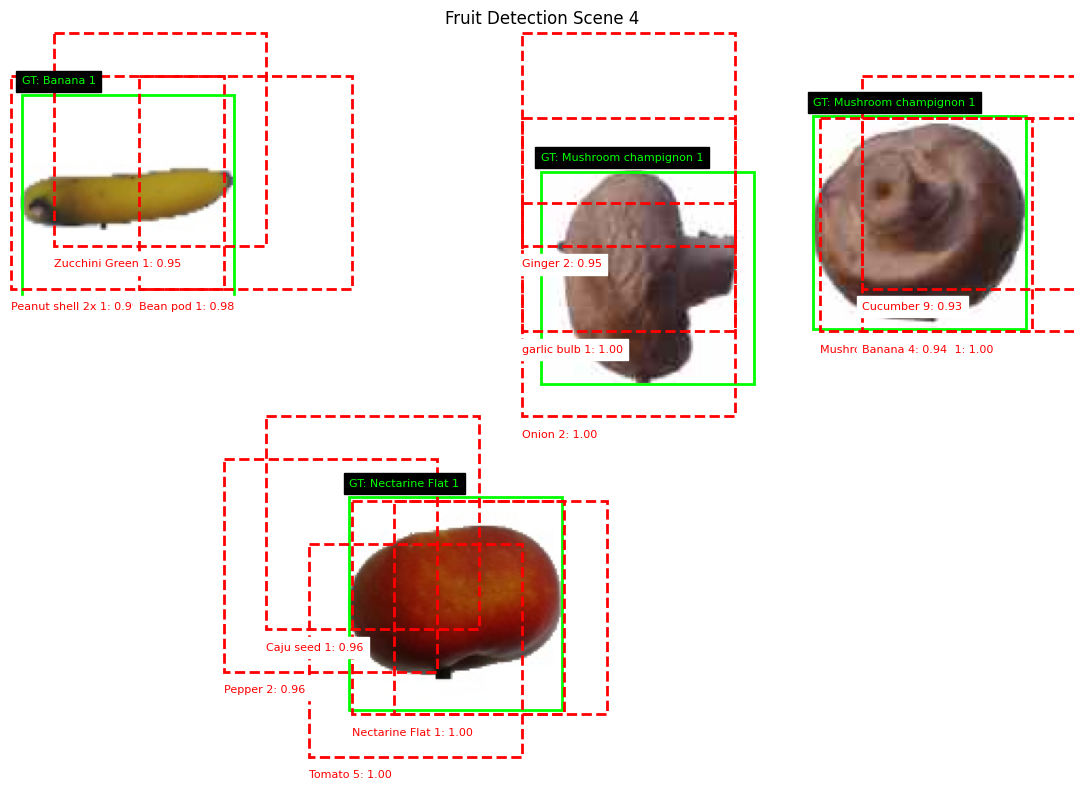

In [57]:
plot_by_stride(detection_results_df, "F1 Score", "F1 Score",
               "Detection F1 Comparison Across Strides and Thresholds",
               PLOTS_DIR / "task4_stride_threshold_f1.png")

plot_by_stride(detection_results_df, "Average Time Per Scene (seconds)",
               "Average Runtime Per Scene (Seconds)",
               "Sliding Window Detection Runtime Comparison",
               PLOTS_DIR / "task4_runtime_comparison.png")

# Show the detector's output on 4 scenes: green = real fruit, red dashed = prediction
for scene_index in range(4):
    scene, gt_boxes, gt_labels = detection_scenes[scene_index]
    boxes, classes, scores, _ = predict_scene_windows(scene, fruit_detector, stride=20)
    detections = apply_nms(boxes, classes, scores, probability_threshold=0.9)

    fig, ax = plt.subplots(figsize=(13, 8))
    ax.imshow(scene)
    draw_boxes(ax, gt_boxes, gt_labels, color="lime", prefix="GT: ",
               text_background="black")
    draw_boxes(ax,
               [d["box"] for d in detections],
               [f"{class_names[d['class_id']]}: {d['score']:.2f}" for d in detections],
               color="red", linestyle="--", text_above=False, text_background="white")
    ax.set_title(f"Fruit Detection Scene {scene_index + 1}")
    ax.axis("off")
    save_and_show(DETECTIONS_DIR / f"detection_scene_{scene_index + 1}.png",
                  bbox_inches="tight")

## SECTION 9 : SAVE MODELS AND PRINT THE FINAL SUMMARY

In [58]:
results["RGB"]["model"].save(MODELS_DIR / "fruit_rgb_classifier.keras")

results["Grayscale"]["model"].save(MODELS_DIR / "fruit_grayscale_classifier.keras")

results["HSV"]["model"].save(MODELS_DIR / "fruit_hsv_classifier.keras")

fruit_detector.save(MODELS_DIR / "fruit_detector_121_class.keras")

print("All Task 4 models saved to:", MODELS_DIR)

task4_summary = pd.DataFrame({
    "Experiment": ["RGB Classification", "Grayscale Classification",
                   "HSV Classification", "121-Class Fruit Detector"],
    "Test Accuracy": [results[s]["test_metrics"]["accuracy"] for s in COLOUR_SPACES] + [np.nan],
    "Top-5 Accuracy": [results[s]["test_metrics"]["top5_accuracy"] for s in COLOUR_SPACES] + [np.nan],
})

print("\nTASK 4 FINAL SUMMARY")

display(task4_summary.round(4))

task4_summary.to_csv(CSV_DIR / "task4_final_summary.csv", index=False)

print("\nBest detection configuration (highest F1)")

best_detection = detection_results_df.loc[detection_results_df["F1 Score"].idxmax()]

display(best_detection.to_frame("Best Result"))

All Task 4 models saved to: /content/Task4_Results/models

TASK 4 FINAL SUMMARY


,Experiment,Test Accuracy,Top-5 Accuracy
0,RGB Classification,0.9498,0.9872
1,Grayscale Classification,0.9355,0.9752
2,HSV Classification,0.9543,0.9852
3,121-Class Fruit Detector,NaN,NaN



Best detection configuration (highest F1)


,Best Result
Stride,20.000000
Probability Threshold,0.900000
True Positives,129.000000
False Positives,603.000000
False Negatives,70.000000
Precision,0.176230
Recall,0.648241
F1 Score,0.277121
Average Time Per Scene (seconds),0.282848


## SECTION 10 : 4(e) DISCUSSION AND ANALYSIS

1. Why can a classifier with high test accuracy still produce false detections?

Classification and object detection are different tasks. The classifier is
trained mainly on images with one complete fruit, centered on a white
background. A sliding-window detector also looks at empty background and at
partially visible fruits. Some windows contain incomplete fruit features
that resemble a known class, so the model may give a high probability to
the wrong fruit. Background training and Non-Maximum Suppression reduce
these errors but cannot remove every false detection.

2. How would the detector perform on real fruit-market photographs?

Probably poorly. Fruits-360 images have clean white backgrounds and centered
fruits. Real photographs have different lighting, shadows, cluttered
backgrounds, overlapping objects, different viewing angles and partially
hidden fruits. This difference is called a domain gap.

Modern alternatives:
- YOLO (You Only Look Once) predicts bounding boxes and class
probabilities in a single forward pass, which makes it efficient.
- Faster R-CNN uses a Region Proposal Network to find likely object
regions, then classifies them and refines the boxes. It shares
convolutional features instead of classifying every sliding window
independently.

3. Compare the colour-space results with the published results.

Use the table produced in Section 6. The published values are RGB 98.66%,
Grayscale 95.25% and HSV 96.09%. Differences may come from the dataset
version, preprocessing, random initialization, training configuration and
implementation choices. Do not claim the results match the paper unless the
measured numbers really do.